## ML Assignment 5 - Diabetes Prediction using K-Nearest Neighbors (KNN)


Implement the **K-Nearest Neighbors (KNN)** algorithm on the diabetes.csv dataset to classify whether a patient is diabetic Outcome = 1 or non-diabetic Outcome = 0.

Compute and analyze the following evaluation metrics on the given dataset:
1. **Confusion Matrix** (True Positives, True Negatives, False Positives, False Negatives)
2. **Accuracy**
3. **Error Rate** ($1 - \text{Accuracy}$)
4. **Precision**
5. **Recall** (Sensitivity)


## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Model selection and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Classifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, classification_report, roc_curve, auc, precision_recall_curve,
    ConfusionMatrixDisplay
)

# Plotting aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.dpi': 110
})

print("All required libraries imported successfully!")

All required libraries imported successfully!



## 2. Load and Explore the Dataset

In [2]:
# Load dataset
df = pd.read_csv('diabetes.csv')

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset Shape: 768 rows × 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Detailed dataset info
print("=" * 60)
print("DATASET INFORMATION & TYPES")
print("=" * 60)
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

DATASET INFORMATION & TYPES
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values per column:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [4]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
Pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### 2.1 Target Class Distribution

Non-Diabetic (Outcome = 0): 500 (65.10%)
Diabetic     (Outcome = 1): 268 (34.90%)


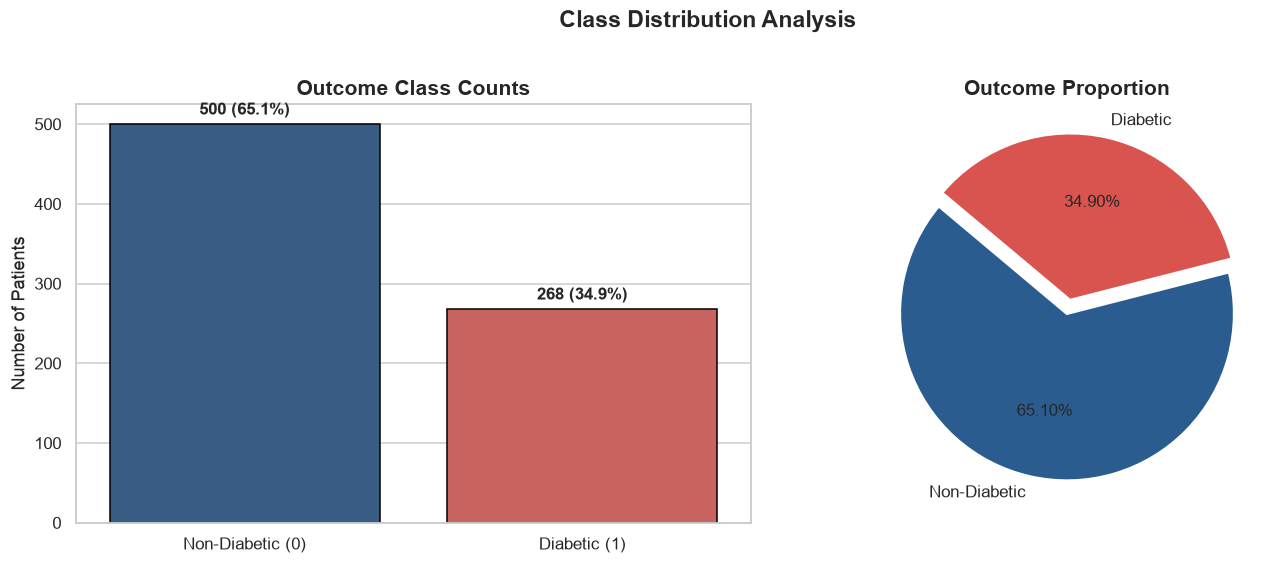

In [5]:
# Count of diabetic vs non-diabetic patients
counts = df['Outcome'].value_counts()
non_diabetic_pct = counts[0] / len(df) * 100
diabetic_pct = counts[1] / len(df) * 100

print(f"Non-Diabetic (Outcome = 0): {counts[0]} ({non_diabetic_pct:.2f}%)")
print(f"Diabetic     (Outcome = 1): {counts[1]} ({diabetic_pct:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
sns.barplot(x=['Non-Diabetic (0)', 'Diabetic (1)'], y=counts.values,
            palette=['#2b5c8f', '#d9534f'], ax=axes[0], edgecolor='black')
axes[0].set_title('Outcome Class Counts', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Patients')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 12, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=['Non-Diabetic', 'Diabetic'], autopct='%1.2f%%',
            colors=['#2b5c8f', '#d9534f'], explode=[0, 0.08], startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Outcome Proportion', fontsize=14, fontweight='bold')

plt.suptitle('Class Distribution Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Data Cleaning & Handling Biological Zeros

In [6]:
# Features where 0 represents missing biological data
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Counts of zero values (missing medical measurements):")
print("-" * 50)
for col in zero_cols:
    num_zeros = (df[col] == 0).sum()
    pct_zeros = (num_zeros / len(df)) * 100
    print(f"{col:<15}: {num_zeros:>4} zero entries ({pct_zeros:.2f}%)")
print("-" * 50)

# Create a clean copy and replace 0 with NaN for imputation
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

# Impute missing values with median per Outcome group (preserves class-specific distributions)
for col in zero_cols:
    df_clean[col] = df_clean.groupby('Outcome')[col].transform(lambda x: x.fillna(x.median()))

print("\nZero values successfully imputed with group medians.")
print(f"Remaining missing values across dataset: {df_clean.isnull().sum().sum()}")

Counts of zero values (missing medical measurements):
--------------------------------------------------
Glucose        :    5 zero entries (0.65%)
BloodPressure  :   35 zero entries (4.56%)
SkinThickness  :  227 zero entries (29.56%)
Insulin        :  374 zero entries (48.70%)
BMI            :   11 zero entries (1.43%)
--------------------------------------------------

Zero values successfully imputed with group medians.
Remaining missing values across dataset: 0


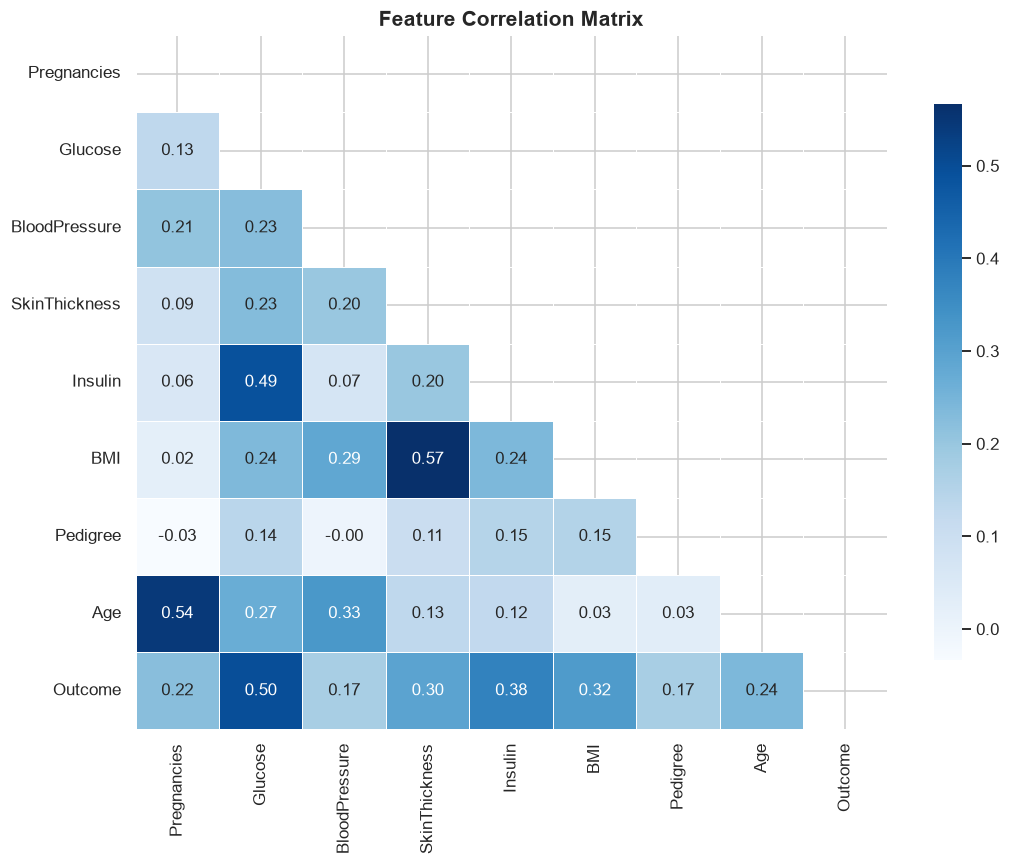

In [7]:
# Feature Correlation Heatmap
plt.figure(figsize=(10, 8))
corr = df_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Feature Selection, Train-Test Split & Normalization

In [8]:
# Separate features (X) and target (y)
feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'Pedigree', 'Age']

X = df_clean[feature_cols].values
y = df_clean['Outcome'].values

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape : {y.shape}")

Feature matrix shape: (768, 8)
Target vector shape : (768,)


In [9]:
# Train-Test Split (80:20)
# stratify=y guarantees the same diabetic/non-diabetic ratio in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set samples: {X_train.shape[0]}")
print(f"Testing set samples : {X_test.shape[0]}")
print(f"Training diabetic ratio: {y_train.mean()*100:.2f}%")
print(f"Testing diabetic ratio : {y_test.mean()*100:.2f}%")

Training set samples: 614
Testing set samples : 154
Training diabetic ratio: 34.85%
Testing diabetic ratio : 35.06%


In [10]:
# Standardize features (fitted strictly on training set to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Feature Normalization Complete (StandardScaler).")
print(f"  X_train_scaled mean : {X_train_scaled.mean():.4f} (centered around 0)")
print(f"  X_train_scaled std  : {X_train_scaled.std():.4f} (unit variance)")

Feature Normalization Complete (StandardScaler).
  X_train_scaled mean : 0.0000 (centered around 0)
  X_train_scaled std  : 1.0000 (unit variance)


## 5. Hyperparameter Tuning: Finding the Optimal K

In [11]:
# Test K values from 1 to 30 using Error Rate & 10-Fold Cross-Validation
k_values = range(1, 31)
test_error_rates = []
cv_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    
    # Test error
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    test_error_rates.append(1.0 - accuracy_score(y_test, y_pred_temp))
    
    # 10-Fold CV accuracy
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

# Determine best K (prefer odd numbers to avoid ties in binary voting)
best_k_cv = k_values[np.argmax(cv_scores)]
best_k_err = k_values[np.argmin(test_error_rates)]

print(f"Optimal K based on 10-Fold Cross-Validation: K = {best_k_cv} (CV Accuracy: {max(cv_scores)*100:.2f}%)")
print(f"Optimal K based on Minimum Test Error Rate: K = {best_k_err} (Test Error: {min(test_error_rates)*100:.2f}%)")

# Choose best odd K
best_k = best_k_cv if best_k_cv % 2 != 0 else (best_k_cv + 1)
print(f"Selected Optimal K for Model: K = {best_k}")

Optimal K based on 10-Fold Cross-Validation: K = 17 (CV Accuracy: 82.42%)
Optimal K based on Minimum Test Error Rate: K = 4 (Test Error: 18.18%)
Selected Optimal K for Model: K = 17


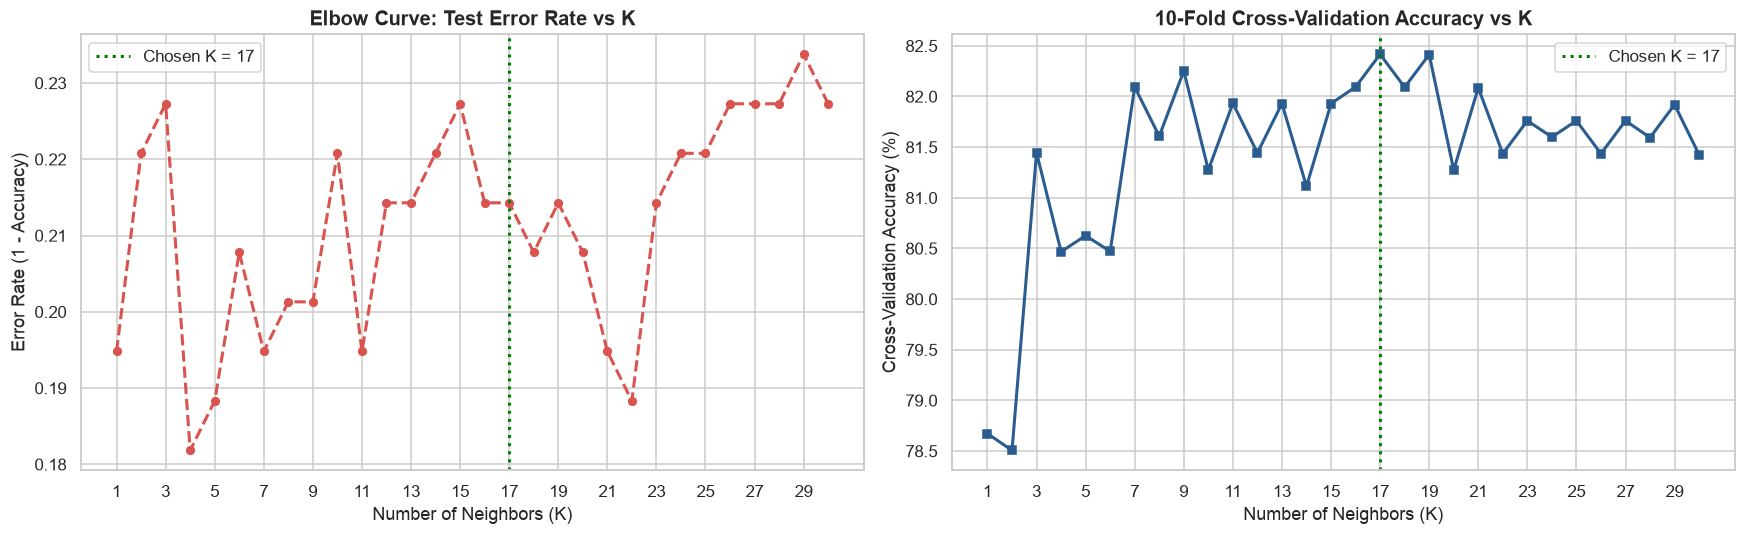

In [12]:
# Plot Elbow Curve (Error Rate) and CV Accuracy Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Elbow Method: Error Rate vs K
axes[0].plot(k_values, test_error_rates, 'o--', color='#d9534f', lw=2, markersize=5)
axes[0].axvline(x=best_k, color='green', linestyle=':', lw=2, label=f'Chosen K = {best_k}')
axes[0].set_title('Elbow Curve: Test Error Rate vs K', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Neighbors (K)')
axes[0].set_ylabel('Error Rate (1 - Accuracy)')
axes[0].set_xticks(range(1, 31, 2))
axes[0].legend()

# 2. 10-Fold Cross-Validation Accuracy vs K
axes[1].plot(k_values, [s * 100 for s in cv_scores], 's-', color='#2b5c8f', lw=2, markersize=5)
axes[1].axvline(x=best_k, color='green', linestyle=':', lw=2, label=f'Chosen K = {best_k}')
axes[1].set_title('10-Fold Cross-Validation Accuracy vs K', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Neighbors (K)')
axes[1].set_ylabel('Cross-Validation Accuracy (%)')
axes[1].set_xticks(range(1, 31, 2))
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Train the Optimal KNN Classifier

In [13]:
# Initialize and fit KNN with optimal K
knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean', weights='distance')
knn.fit(X_train_scaled, y_train)

# Predictions on training and testing sets
y_pred_train = knn.predict(X_train_scaled)
y_pred_test  = knn.predict(X_test_scaled)
y_prob_test  = knn.predict_proba(X_test_scaled)[:, 1]

print(f"KNN Model successfully trained with K = {best_k}!")

KNN Model successfully trained with K = 17!



## 7. Compute Required Evaluation Metrics

### Mathematical Definitions

Confusion Matrix:
$$
\begin{pmatrix}
\text{TN} & \text{FP} \\
\text{FN} & \text{TP}
\end{pmatrix}
$$

1. **Accuracy:** Overall proportion of correct predictions
   $$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

2. **Error Rate:** Proportion of misclassified samples
   $$\text{Error Rate} = 1 - \text{Accuracy} = \frac{\text{FP} + \text{FN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$

3. **Precision (Positive Predictive Value):** Proportion of predicted diabetic patients who actually have diabetes
   $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

4. **Recall (Sensitivity / True Positive Rate):** Proportion of actual diabetic patients correctly diagnosed by model
   $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

5. **Specificity (True Negative Rate):** Proportion of healthy patients correctly identified as non-diabetic
   $$\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}$$

6. **F1-Score:** Harmonic mean of Precision and Recall
   $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [14]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

# Compute all metrics
total_samples = len(y_test)
accuracy      = (tp + tn) / total_samples
error_rate    = (fp + fn) / total_samples
precision     = tp / (tp + fp) if (tp + fp) > 0 else 0
recall        = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity   = tn / (tn + fp) if (tn + fp) > 0 else 0
f1            = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# Print Results in a clean formatted report
print("=" * 65)
print(f"      EVALUATION METRICS SUMMARY (K = {best_k} Neighbors)")
print("=" * 65)
print(f"  1. True Positives  (TP - Diabetic correctly identified)   : {tp}")
print(f"  2. True Negatives  (TN - Healthy correctly identified)    : {tn}")
print(f"  3. False Positives (FP - Type I Error, Healthy as Diabetic): {fp}")
print(f"  4. False Negatives (FN - Type II Error, Diabetic missed)  : {fn}")
print("-" * 65)
print(f"  🎯 ACCURACY                  : {accuracy * 100:.2f}%")
print(f"  ❌ ERROR RATE (1 - Accuracy) : {error_rate * 100:.2f}%")
print(f"  🎯 PRECISION                 : {precision * 100:.2f}%")
print(f"  🎯 RECALL (Sensitivity)      : {recall * 100:.2f}%")
print(f"  🔍 SPECIFICITY               : {specificity * 100:.2f}%")
print(f"  ⚖️ F1-SCORE                  : {f1 * 100:.2f}%")
print("=" * 65)

print("\nDetailed Classification Report from Scikit-Learn:")
print(classification_report(y_test, y_pred_test, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))

      EVALUATION METRICS SUMMARY (K = 17 Neighbors)
  1. True Positives  (TP - Diabetic correctly identified)   : 36
  2. True Negatives  (TN - Healthy correctly identified)    : 85
  3. False Positives (FP - Type I Error, Healthy as Diabetic): 15
  4. False Negatives (FN - Type II Error, Diabetic missed)  : 18
-----------------------------------------------------------------
  🎯 ACCURACY                  : 78.57%
  ❌ ERROR RATE (1 - Accuracy) : 21.43%
  🎯 PRECISION                 : 70.59%
  🎯 RECALL (Sensitivity)      : 66.67%
  🔍 SPECIFICITY               : 85.00%
  ⚖️ F1-SCORE                  : 68.57%

Detailed Classification Report from Scikit-Learn:
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.83      0.85      0.84       100
    Diabetic (1)       0.71      0.67      0.69        54

        accuracy                           0.79       154
       macro avg       0.77      0.76      0.76       154
    weighted avg       0.78      0.79      

### 7.1 Confusion Matrix Visualization

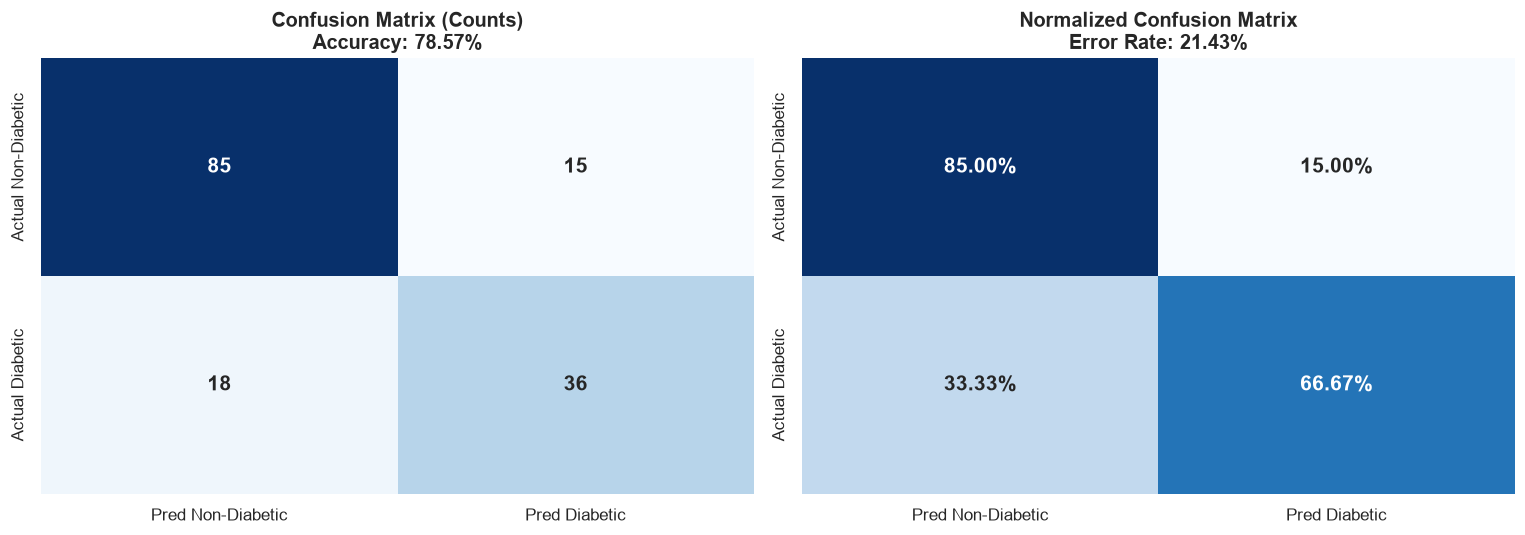

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix (Counts)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Non-Diabetic', 'Pred Diabetic'],
            yticklabels=['Actual Non-Diabetic', 'Actual Diabetic'], ax=axes[0],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'Confusion Matrix (Counts)\nAccuracy: {accuracy*100:.2f}%', fontsize=13, fontweight='bold')

# 2. Confusion Matrix (Normalized Percentages)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', cbar=False,
            xticklabels=['Pred Non-Diabetic', 'Pred Diabetic'],
            yticklabels=['Actual Non-Diabetic', 'Actual Diabetic'], ax=axes[1],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'Normalized Confusion Matrix\nError Rate: {error_rate*100:.2f}%', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### 7.2 ROC Curve & Precision-Recall Curve

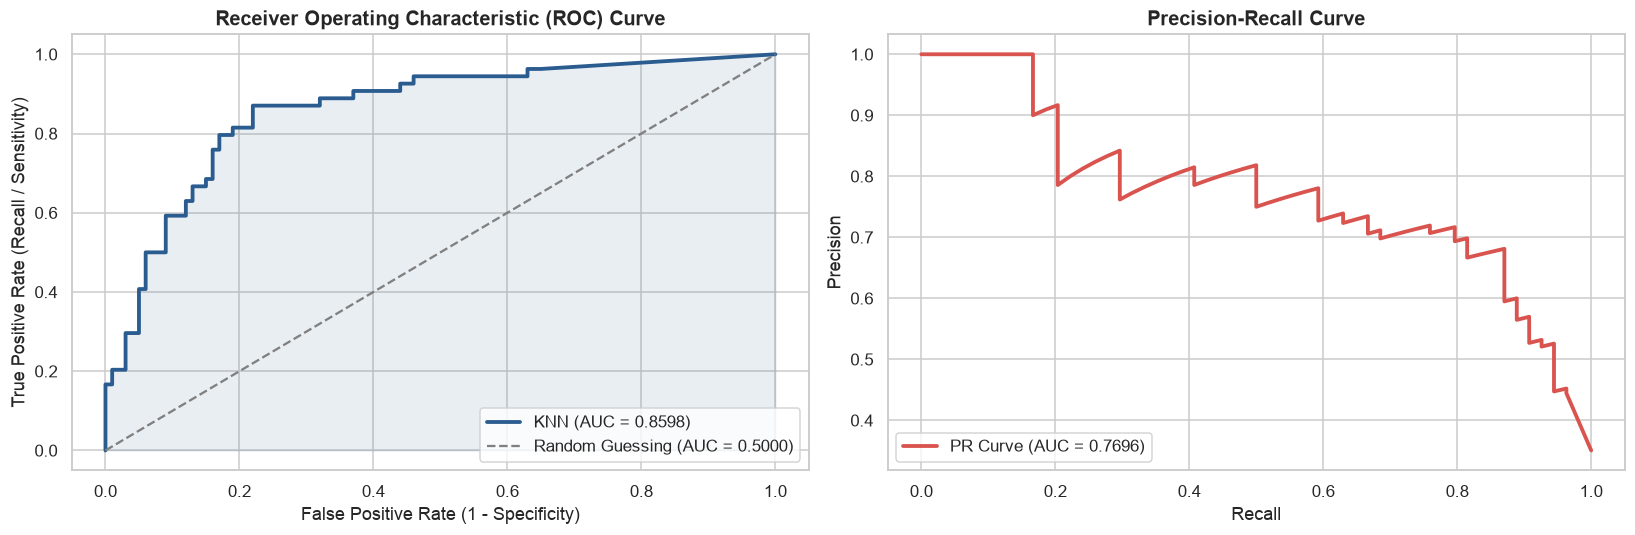

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'KNN (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.5000)')
axes[0].fill_between(fpr, tpr, alpha=0.10, color='#2b5c8f')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)')
axes[0].legend(loc='lower right')

# 2. Precision-Recall Curve
prec_vals, rec_vals, _ = precision_recall_curve(y_test, y_prob_test)
pr_auc = auc(rec_vals, prec_vals)

axes[1].plot(rec_vals, prec_vals, color='#d9534f', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


## 8. KNN Implementation from Scratch

To demonstrate a deep understanding of the KNN mechanism, below is an implementation from first principles:
1. Calculate Euclidean distance from query point to all training points: $d(x, x') = \sqrt{\sum_{j=1}^D (x_j - x'_j)^2}$
2. Sort distances in ascending order.
3. Select the labels of the K closest neighbors.
4. Predict the majority voting class.

In [17]:
class KNNFromScratch:
    def __init__(self, k=5):
        self.k = k
        
    def fit(self, X, y):
        # KNN is a lazy learner (memorizes training data)
        self.X_train = np.array(X)
        self.y_train = np.array(y)
        
    def _euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))
        
    def predict(self, X):
        predictions = [self._predict_single(x) for x in np.array(X)]
        return np.array(predictions)
        
    def _predict_single(self, x):
        # 1. Compute distances to all training points
        distances = [self._euclidean_distance(x, x_train) for x_train in self.X_train]
        
        # 2. Get indices of K nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
        
        # 3. Retrieve labels of K nearest neighbors
        k_labels = [self.y_train[i] for i in k_indices]
        
        # 4. Majority voting
        most_common = 1 if sum(k_labels) > (self.k / 2) else 0
        return most_common

# Run scratch KNN
knn_scratch = KNNFromScratch(k=best_k)
knn_scratch.fit(X_train_scaled, y_train)
y_pred_scratch = knn_scratch.predict(X_test_scaled)

scratch_acc = accuracy_score(y_test, y_pred_scratch)
print("=" * 55)
print("VERIFICATION: SCRATCH KNN vs SCIKIT-LEARN")
print("=" * 55)
print(f"Scratch KNN Accuracy      : {scratch_acc * 100:.2f}%")
print(f"Scikit-Learn Accuracy     : {accuracy * 100:.2f}%")
print(f"Prediction agreement rate : {(y_pred_scratch == y_pred_test).mean() * 100:.2f}%")
print("=" * 55)

VERIFICATION: SCRATCH KNN vs SCIKIT-LEARN
Scratch KNN Accuracy      : 78.57%
Scikit-Learn Accuracy     : 78.57%
Prediction agreement rate : 100.00%



## 9. Making a Prediction for a New Patient

In [18]:
# Example new patient clinical profile
# Pregnancies=2, Glucose=145, BloodPressure=75, SkinThickness=30, Insulin=160, BMI=32.5, Pedigree=0.55, Age=45
sample_patient = pd.DataFrame([{
    'Pregnancies': 2,
    'Glucose': 145,
    'BloodPressure': 75,
    'SkinThickness': 30,
    'Insulin': 160,
    'BMI': 32.5,
    'Pedigree': 0.55,
    'Age': 45
}])

# Scale using the pre-fitted scaler
sample_scaled = scaler.transform(sample_patient)

# Predict Outcome and Probability
pred_class = knn.predict(sample_scaled)[0]
pred_proba = knn.predict_proba(sample_scaled)[0]

print("=" * 55)
print("          NEW PATIENT DIAGNOSTIC PREDICTION")
print("=" * 55)
print("Patient Diagnostic Data:")
for col, val in sample_patient.iloc[0].items():
    print(f"  {col:<16}: {val}")
print("-" * 55)
print(f"Probability of Diabetes : {pred_proba[1] * 100:.2f}%")
print(f"Predicted Diagnosis     : {'⚠️ Diabetic (Positive)' if pred_class == 1 else '✅ Non-Diabetic (Negative)'}")
print("=" * 55)

          NEW PATIENT DIAGNOSTIC PREDICTION
Patient Diagnostic Data:
  Pregnancies     : 2.0
  Glucose         : 145.0
  BloodPressure   : 75.0
  SkinThickness   : 30.0
  Insulin         : 160.0
  BMI             : 32.5
  Pedigree        : 0.55
  Age             : 45.0
-------------------------------------------------------
Probability of Diabetes : 71.13%
Predicted Diagnosis     : ⚠️ Diabetic (Positive)
